# Exploratory Data Analysis — Bike Sharing

## Mục tiêu
Khám phá dữ liệu thuê xe đạp theo thời gian để hiểu tần suất ghi nhận, xu hướng, mùa vụ, dữ liệu thiếu hoặc thời điểm bị khuyết, và mối liên hệ giữa nhu cầu thuê xe với các yếu tố sẵn có.

## Định hướng
Đây là bài toán chuỗi thời gian. Thứ tự thời gian cần được giữ nguyên khi phân tích và chia dữ liệu. Các đặc trưng dùng dự đoán chỉ nên dựa trên thông tin có thể biết tại thời điểm dự báo để tránh rò rỉ dữ liệu.

## Lưu ý
Cách phân tích phụ thuộc vào độ phân giải dữ liệu (ví dụ: theo giờ hoặc theo ngày), cột thời gian và cột mục tiêu trong bộ dữ liệu.

Data Loading

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RAW_DIR = Path("../data/raw")
HOUR_PATH = RAW_DIR / "hour.csv"
DAY_PATH = RAW_DIR / "day.csv"

for path in [HOUR_PATH, DAY_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {path.resolve()}")

hour_df = pd.read_csv(HOUR_PATH)
day_df = pd.read_csv(DAY_PATH)

# Chuẩn hóa nhẹ tên cột
for frame in [hour_df, day_df]:
    frame.columns = frame.columns.astype(str).str.strip().str.lower()

# Chuyển cột ngày thành datetime
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"], errors="coerce")
day_df["dteday"] = pd.to_datetime(day_df["dteday"], errors="coerce")

# Tạo mốc thời gian đầy đủ cho từng bản ghi theo giờ
hour_df["timestamp"] = (
    hour_df["dteday"]
    + pd.to_timedelta(hour_df["hr"], unit="h")
)

# Sắp xếp theo thời gian
hour_df = hour_df.sort_values("timestamp").reset_index(drop=True)
day_df = day_df.sort_values("dteday").reset_index(drop=True)

# Chọn dữ liệu giờ làm bộ dữ liệu chính cho notebook
df = hour_df.copy()

TIME_COL = "timestamp"
TARGET = "cnt"

print("Hourly:", hour_df.shape)
print("Daily:", day_df.shape)
print("Khoảng thời gian hourly:",
      hour_df[TIME_COL].min(), "→", hour_df[TIME_COL].max())
print("Số timestamp khác nhau:", hour_df[TIME_COL].nunique())
print("Tên cột hourly:", hour_df.columns.tolist())

display(hour_df.head())
display(day_df.head())

Hourly: (17379, 18)
Daily: (731, 16)
Khoảng thời gian hourly: 2011-01-01 00:00:00 → 2012-12-31 23:00:00
Số timestamp khác nhau: 17379
Tên cột hourly: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'timestamp']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Dataset Overview

In [6]:
print("Hourly dataset")
print(f"Kích thước: {hour_df.shape[0]:,} dòng × {hour_df.shape[1]} cột")
print(f"Số ngày có dữ liệu: {hour_df['dteday'].nunique():,}")
print(f"Khoảng thời gian: {hour_df['timestamp'].min()} → {hour_df['timestamp'].max()}")

display(
    pd.DataFrame({
        "data_type": hour_df.dtypes.astype(str),
        "missing": hour_df.isna().sum(),
        "unique_values": hour_df.nunique(dropna=True),
    })
)

continuous_cols = [
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

display(hour_df[continuous_cols].describe().T)

Hourly dataset
Kích thước: 17,379 dòng × 18 cột
Số ngày có dữ liệu: 731
Khoảng thời gian: 2011-01-01 00:00:00 → 2012-12-31 23:00:00


,data_type,missing,unique_values
instant,int64,0,17379
dteday,datetime64[ns],0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
hr,int64,0,24
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,4


,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000
atemp,17379.0,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000
hum,17379.0,0.627229,0.192930,0.00,0.4800,0.6300,0.7800,1.0000
windspeed,17379.0,0.190098,0.122340,0.00,0.1045,0.1940,0.2537,0.8507
casual,17379.0,35.676218,49.305030,0.00,4.0000,17.0000,48.0000,367.0000
registered,17379.0,153.786869,151.357286,0.00,34.0000,115.0000,220.0000,886.0000
cnt,17379.0,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000


Data Quality

In [7]:
print("Giá trị thiếu theo cột:")
display(hour_df.isna().sum().rename("missing_count").to_frame())

print("Số dòng trùng hoàn toàn:", hour_df.duplicated().sum())
print("Số timestamp bị trùng:", hour_df["timestamp"].duplicated().sum())

# So sánh các timestamp quan sát được với lịch mỗi giờ trong toàn kỳ
expected_hours = pd.date_range(
    start=hour_df["timestamp"].min(),
    end=hour_df["timestamp"].max(),
    freq="h"
)
observed_hours = pd.DatetimeIndex(hour_df["timestamp"].dropna().unique())
missing_hours = expected_hours.difference(observed_hours)

print(f"Số giờ trong lịch liên tục: {len(expected_hours):,}")
print(f"Số timestamp quan sát được: {len(observed_hours):,}")
print(f"Số timestamp không xuất hiện trong dữ liệu: {len(missing_hours):,}")
print("Một số timestamp bị thiếu:", missing_hours[:10].tolist())

print(
    "Số dòng không khớp cnt = casual + registered:",
    (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum()
)

Giá trị thiếu theo cột:


,missing_count
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Số dòng trùng hoàn toàn: 0
Số timestamp bị trùng: 0
Số giờ trong lịch liên tục: 17,544
Số timestamp quan sát được: 17,379
Số timestamp không xuất hiện trong dữ liệu: 165
Một số timestamp bị thiếu: [Timestamp('2011-01-02 05:00:00'), Timestamp('2011-01-03 02:00:00'), Timestamp('2011-01-03 03:00:00'), Timestamp('2011-01-04 03:00:00'), Timestamp('2011-01-05 03:00:00'), Timestamp('2011-01-06 03:00:00'), Timestamp('2011-01-07 03:00:00'), Timestamp('2011-01-11 03:00:00'), Timestamp('2011-01-11 04:00:00'), Timestamp('2011-01-12 03:00:00')]
Số dòng không khớp cnt = casual + registered: 0


In [8]:
gap_info = pd.DataFrame({
    "current_timestamp": hour_df["timestamp"].sort_values().reset_index(drop=True)
})

gap_info["previous_timestamp"] = gap_info["current_timestamp"].shift()
gap_info["gap_hours"] = (
    gap_info["current_timestamp"] - gap_info["previous_timestamp"]
).dt.total_seconds() / 3600

gaps = gap_info.loc[gap_info["gap_hours"] > 1].copy()
gaps["missing_hours_before_row"] = gaps["gap_hours"] - 1

print("Số khoảng thời gian bị gián đoạn:", len(gaps))
display(gaps.sort_values("missing_hours_before_row", ascending=False).head(15))

missing_by_day = (
    pd.Series(1, index=pd.DatetimeIndex(missing_hours))
    .resample("D")
    .sum()
)
missing_by_day = missing_by_day[missing_by_day > 0].sort_values(ascending=False)

print("Số ngày có ít nhất một timestamp không xuất hiện:", len(missing_by_day))
display(missing_by_day.head(15).rename("missing_hours").to_frame())

Số khoảng thời gian bị gián đoạn: 75


,current_timestamp,previous_timestamp,gap_hours,missing_hours_before_row
15884,2012-10-30 13:00:00,2012-10-29 00:00:00,37.0,36.0
587,2011-01-27 16:00:00,2011-01-26 17:00:00,23.0,22.0
5636,2011-08-28 07:00:00,2011-08-27 17:00:00,14.0,13.0
396,2011-01-18 12:00:00,2011-01-17 23:00:00,13.0,12.0
1181,2011-02-22 06:00:00,2011-02-21 23:00:00,7.0,6.0
926,2011-02-11 05:00:00,2011-02-11 02:00:00,3.0,2.0
574,2011-01-26 05:00:00,2011-01-26 02:00:00,3.0,2.0
1554,2011-03-10 05:00:00,2011-03-10 02:00:00,3.0,2.0
236,2011-01-11 05:00:00,2011-01-11 02:00:00,3.0,2.0
258,2011-01-12 05:00:00,2011-01-12 02:00:00,3.0,2.0


Số ngày có ít nhất một timestamp không xuất hiện: 76


,missing_hours
2012-10-29,23
2011-01-27,16
2012-10-30,13
2011-01-18,12
2011-01-26,8
2011-08-28,7
2011-02-22,6
2011-08-27,6
2011-03-10,2
2011-02-11,2


Univariate Analysis

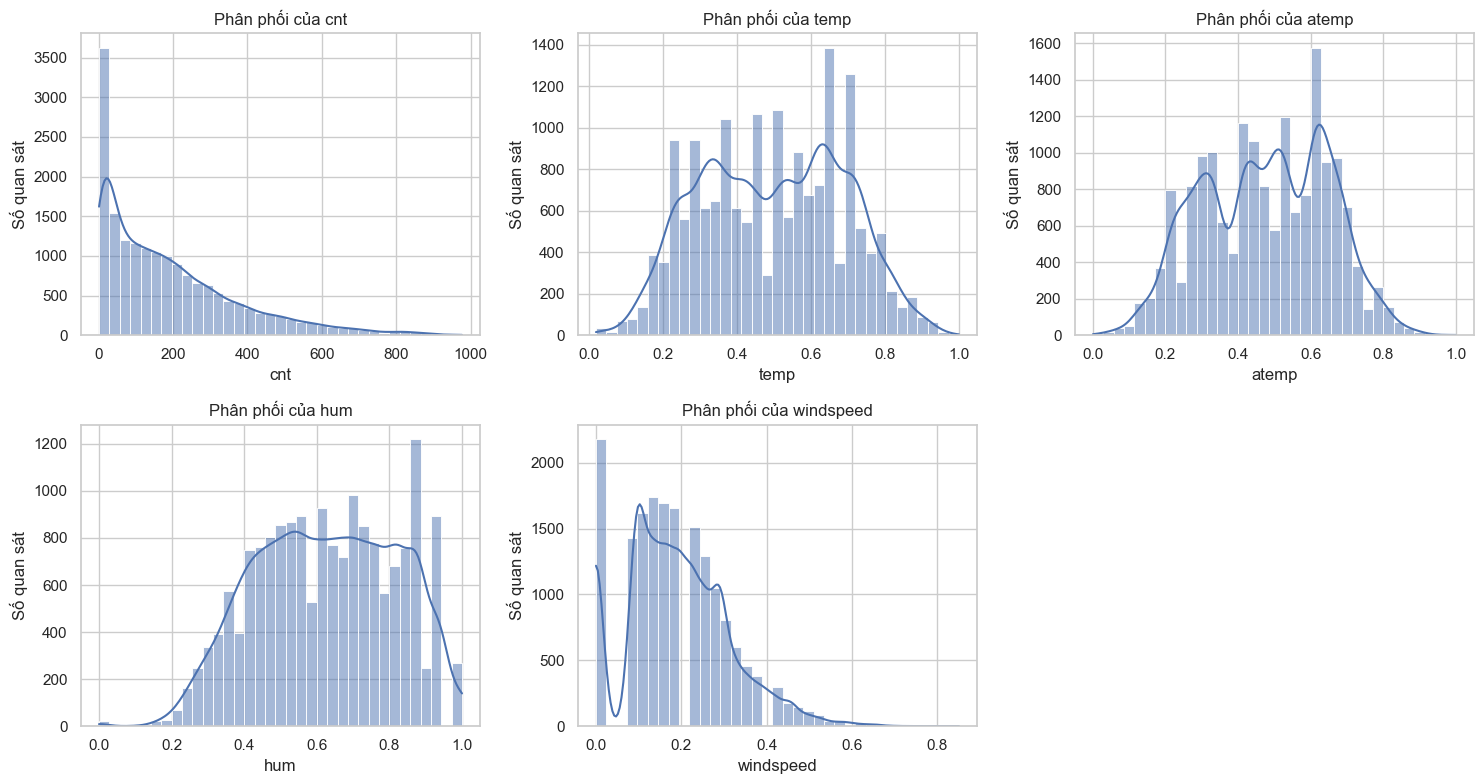

In [9]:
plot_cols = ["cnt", "temp", "atemp", "hum", "windspeed"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    sns.histplot(data=hour_df, x=col, bins=35, kde=True, ax=ax)
    ax.set_title(f"Phân phối của {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Số quan sát")

# Ẩn ô trống cuối cùng
for ax in axes[len(plot_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Bivariate Analysis

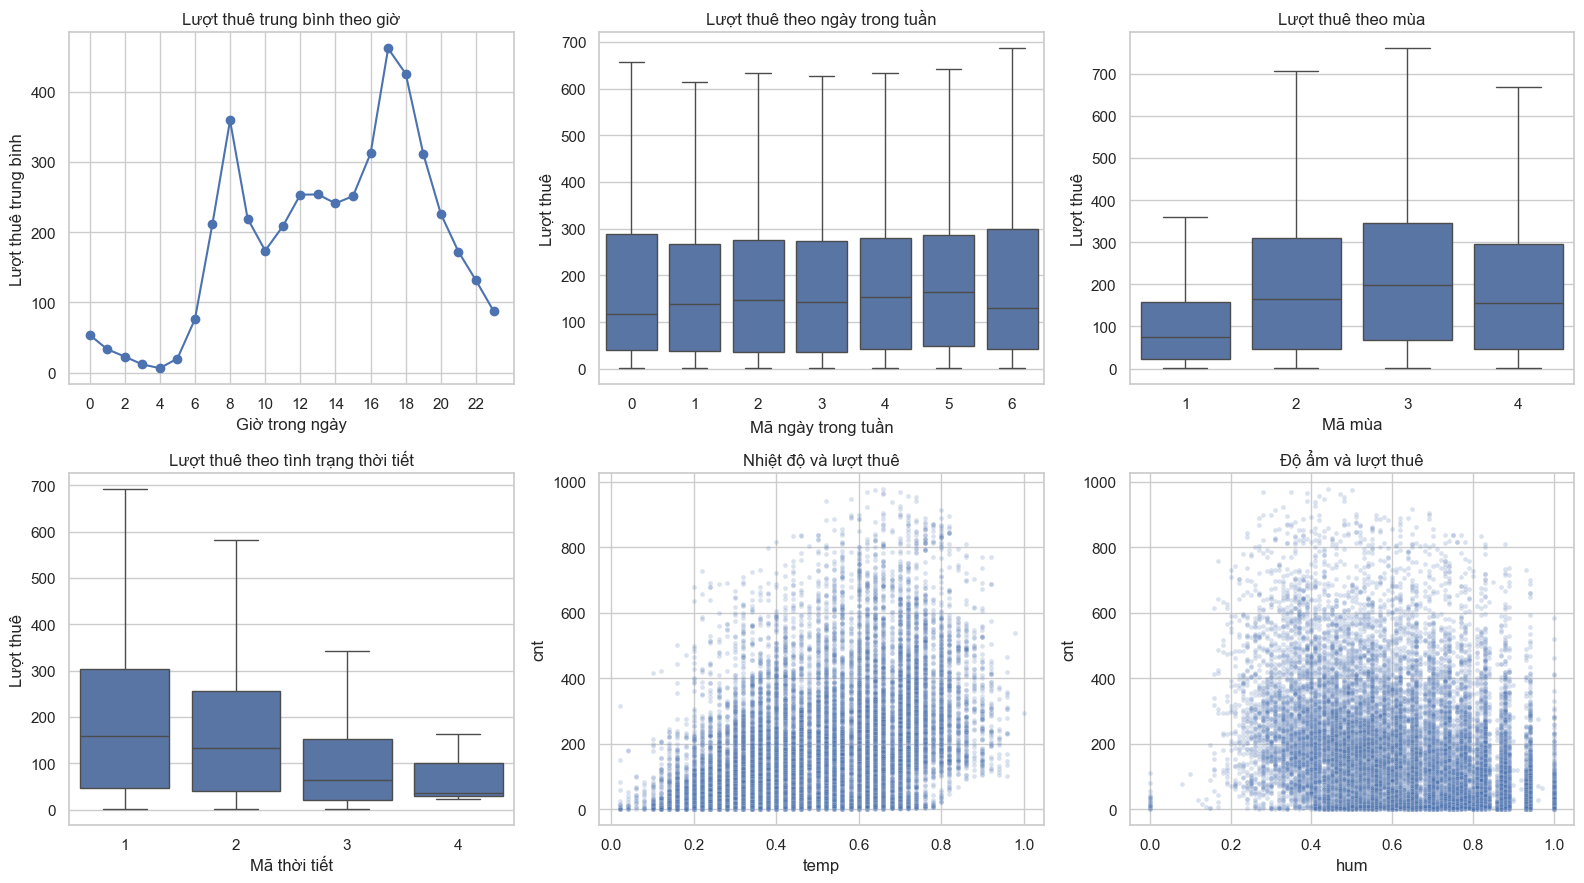

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Lượt thuê trung bình theo giờ trong ngày
hour_mean = hour_df.groupby("hr")["cnt"].mean()
axes[0, 0].plot(hour_mean.index, hour_mean.values, marker="o")
axes[0, 0].set(
    title="Lượt thuê trung bình theo giờ",
    xlabel="Giờ trong ngày",
    ylabel="Lượt thuê trung bình"
)
axes[0, 0].set_xticks(range(0, 24, 2))

# Phân phối lượt thuê theo ngày trong tuần
sns.boxplot(
    data=hour_df, x="weekday", y="cnt",
    showfliers=False, ax=axes[0, 1]
)
axes[0, 1].set(
    title="Lượt thuê theo ngày trong tuần",
    xlabel="Mã ngày trong tuần",
    ylabel="Lượt thuê"
)

# Phân phối lượt thuê theo mùa
sns.boxplot(
    data=hour_df, x="season", y="cnt",
    showfliers=False, ax=axes[0, 2]
)
axes[0, 2].set(
    title="Lượt thuê theo mùa",
    xlabel="Mã mùa",
    ylabel="Lượt thuê"
)

# Phân phối lượt thuê theo tình trạng thời tiết
sns.boxplot(
    data=hour_df, x="weathersit", y="cnt",
    showfliers=False, ax=axes[1, 0]
)
axes[1, 0].set(
    title="Lượt thuê theo tình trạng thời tiết",
    xlabel="Mã thời tiết",
    ylabel="Lượt thuê"
)

# Mối liên hệ giữa nhiệt độ và lượt thuê
sns.scatterplot(
    data=hour_df, x="temp", y="cnt",
    alpha=0.2, s=12, ax=axes[1, 1]
)
axes[1, 1].set(title="Nhiệt độ và lượt thuê")

# Mối liên hệ giữa độ ẩm và lượt thuê
sns.scatterplot(
    data=hour_df, x="hum", y="cnt",
    alpha=0.2, s=12, ax=axes[1, 2]
)
axes[1, 2].set(title="Độ ẩm và lượt thuê")

plt.tight_layout()
plt.show()

Target Analysis

Số ngày không khớp tổng day.csv và tổng hour.csv: 0
Độ lệch tuyệt đối lớn nhất: 0
Số giờ có bản ghi theo từng ngày:


,number_of_days
observed_hours,
1,1
8,1
11,1
12,1
16,1
17,1
18,2
22,6
23,62


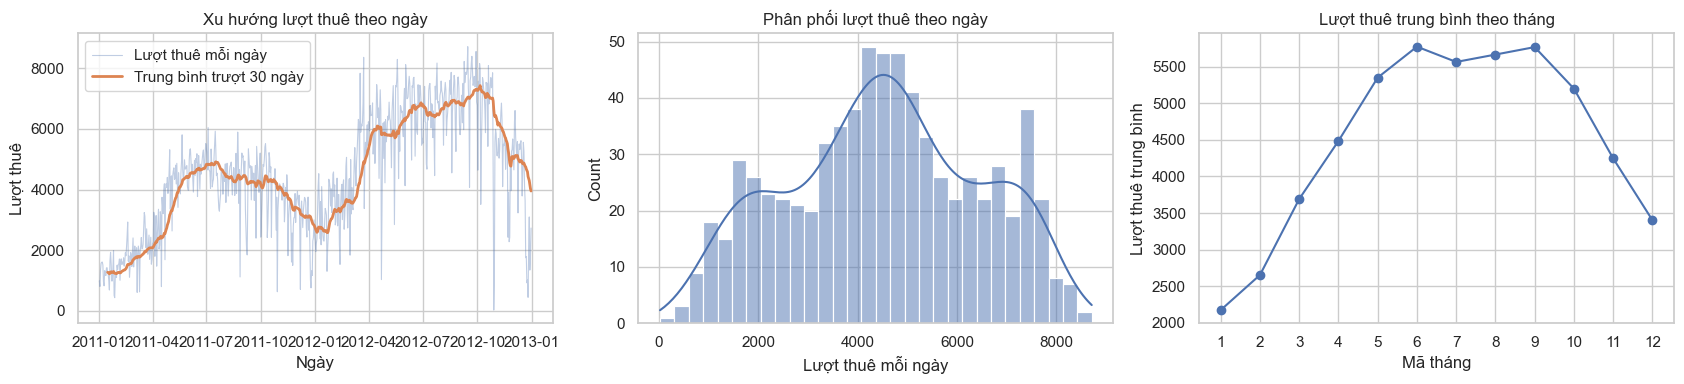

In [11]:
# Đối chiếu tổng lượt thuê theo giờ với tổng lượt thuê trong day.csv
hourly_daily = (
    hour_df.groupby("dteday", as_index=False)
    .agg(
        hourly_cnt_sum=("cnt", "sum"),
        observed_hours=("hr", "nunique")
    )
)

daily_compare = day_df[["dteday", "cnt"]].merge(
    hourly_daily,
    on="dteday",
    how="left"
)

daily_compare["difference"] = (
    daily_compare["cnt"] - daily_compare["hourly_cnt_sum"]
)

mismatches = daily_compare[daily_compare["difference"] != 0]

print("Số ngày không khớp tổng day.csv và tổng hour.csv:", len(mismatches))
print("Độ lệch tuyệt đối lớn nhất:", daily_compare["difference"].abs().max())
print("Số giờ có bản ghi theo từng ngày:")
display(daily_compare["observed_hours"].value_counts().sort_index().rename("number_of_days").to_frame())

if not mismatches.empty:
    display(
        mismatches.assign(
            abs_difference=mismatches["difference"].abs()
        )
        .sort_values("abs_difference", ascending=False)
        .head(10)
    )

# Phân tích mục tiêu ở độ phân giải ngày
daily_target = day_df.sort_values("dteday").copy()
daily_target["rolling_30d"] = daily_target["cnt"].rolling(
    window=30, min_periods=15
).mean()

monthly_mean = daily_target.groupby("mnth")["cnt"].mean()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(
    daily_target["dteday"], daily_target["cnt"],
    alpha=0.35, linewidth=0.8, label="Lượt thuê mỗi ngày"
)
axes[0].plot(
    daily_target["dteday"], daily_target["rolling_30d"],
    linewidth=2, label="Trung bình trượt 30 ngày"
)
axes[0].set_title("Xu hướng lượt thuê theo ngày")
axes[0].set_xlabel("Ngày")
axes[0].set_ylabel("Lượt thuê")
axes[0].legend()

sns.histplot(data=daily_target, x="cnt", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Phân phối lượt thuê theo ngày")
axes[1].set_xlabel("Lượt thuê mỗi ngày")

axes[2].plot(monthly_mean.index, monthly_mean.values, marker="o")
axes[2].set_title("Lượt thuê trung bình theo tháng")
axes[2].set_xlabel("Mã tháng")
axes[2].set_ylabel("Lượt thuê trung bình")
axes[2].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

Domain-specific EDA

Số giờ sau khi dựng lại lịch: 17544
Số giờ không có lượt thuê: 165


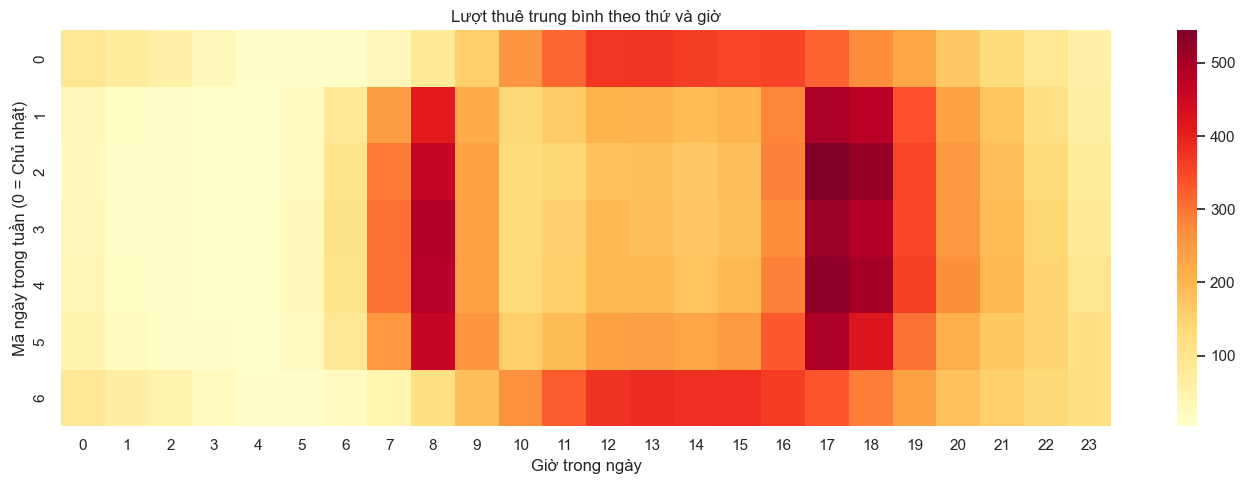

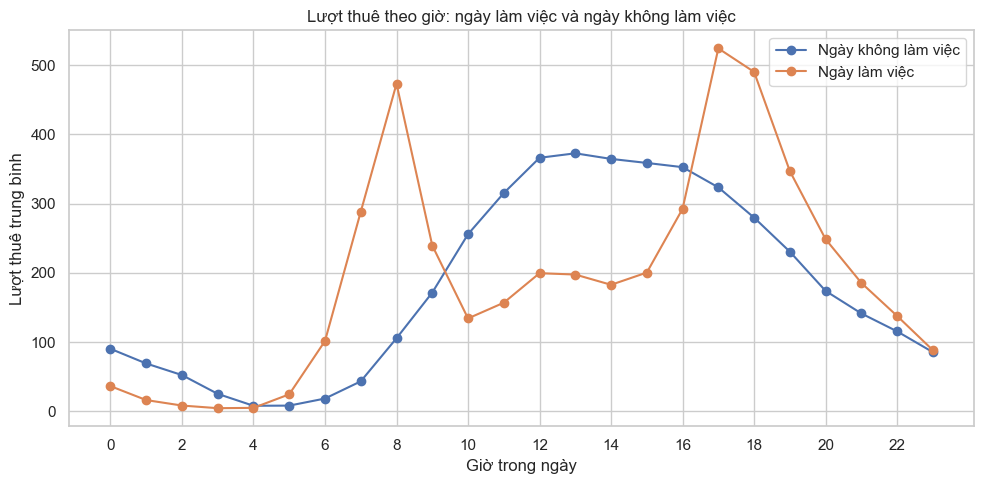

In [12]:
# Tạo lịch giờ đầy đủ trong một DataFrame phân tích riêng
hourly_calendar = pd.DataFrame(
    index=pd.date_range(
        start=hour_df["timestamp"].min(),
        end=hour_df["timestamp"].max(),
        freq="h"
    )
)
hourly_calendar.index.name = "timestamp"

# Gắn các số lượt thuê đã quan sát
count_cols = ["cnt", "casual", "registered"]
hourly_calendar = hourly_calendar.join(
    hour_df.set_index("timestamp")[count_cols]
)

# Đối chiếu daily/hourly cho thấy các giờ vắng dòng có tổng lượt thuê bằng 0
hourly_calendar[count_cols] = hourly_calendar[count_cols].fillna(0)

# Gắn thông tin cấp ngày từ day.csv
hourly_calendar["dteday"] = hourly_calendar.index.normalize()

daily_context = day_df.set_index("dteday")[
    ["workingday", "season", "weathersit", "holiday"]
]

hourly_calendar = hourly_calendar.join(daily_context, on="dteday")
hourly_calendar["hr"] = hourly_calendar.index.hour
hourly_calendar["weekday"] = (hourly_calendar.index.dayofweek + 1) % 7

print("Số giờ sau khi dựng lại lịch:", len(hourly_calendar))
print("Số giờ không có lượt thuê:", int((hourly_calendar["cnt"] == 0).sum()))

# Heatmap nhu cầu theo thứ trong tuần và giờ
weekday_hour_mean = hourly_calendar.pivot_table(
    index="weekday",
    columns="hr",
    values="cnt",
    aggfunc="mean"
)

plt.figure(figsize=(14, 5))
sns.heatmap(weekday_hour_mean, cmap="YlOrRd")
plt.title("Lượt thuê trung bình theo thứ và giờ")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Mã ngày trong tuần (0 = Chủ nhật)")
plt.tight_layout()
plt.show()

# So sánh nhu cầu theo giờ giữa ngày làm việc và ngày không làm việc
workday_hour_mean = (
    hourly_calendar.groupby(["workingday", "hr"])["cnt"]
    .mean()
    .unstack("workingday")
)

plt.figure(figsize=(10, 5))
for col, label in [(0, "Ngày không làm việc"), (1, "Ngày làm việc")]:
    if col in workday_hour_mean.columns:
        plt.plot(
            workday_hour_mean.index,
            workday_hour_mean[col],
            marker="o",
            label=label
        )

plt.title("Lượt thuê theo giờ: ngày làm việc và ngày không làm việc")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Lượt thuê trung bình")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.tight_layout()
plt.show()

EDA Conclusion

- Bộ dữ liệu gồm hai mức thời gian: `hour.csv` có 17.379 dòng và 17 cột gốc; `day.csv` có 731 dòng và 16 cột gốc. Dữ liệu bao phủ từ năm 2011 đến hết năm 2012. Trong notebook, `timestamp` được tạo từ `dteday` và `hr` để phân tích chuỗi theo giờ.
- Không phát hiện giá trị null, dòng trùng hoặc timestamp trùng. Lịch giờ liên tục có 17.544 mốc, trong khi dữ liệu có 17.379 timestamp: thiếu 165 mốc, thuộc 75 khoảng gián đoạn trên 76 ngày. Tổng `cnt` theo giờ khớp chính xác với `day.csv` ở cả 731 ngày. Vì vậy, khi dựng lịch giờ trong notebook, các giờ vắng bản ghi có thể được xem là giờ có 0 lượt thuê; chỉ điền 0 cho các cột số lượt thuê.
- Phân phối `cnt` theo giờ lệch phải và có độ biến động lớn. Nhu cầu theo ngày có xu hướng mùa vụ: mức trung bình thấp vào đầu năm, tăng cao khoảng tháng 6–9 rồi giảm về cuối năm.
- Nhu cầu theo giờ khác nhau giữa ngày làm việc và ngày không làm việc. Ngày làm việc có các đỉnh vào khoảng 8 giờ và 17–18 giờ; ngày không làm việc có nhu cầu cao hơn vào giữa ngày.
- Lượt thuê có xu hướng cao hơn khi nhiệt độ tăng và thấp hơn ở nhóm thời tiết bất lợi. Đây là các mối liên hệ quan sát được, không khẳng định quan hệ nhân quả.
- Khi dự báo tổng lượt thuê `cnt`, không dùng `casual` và `registered` làm biến đầu vào vì tổng của chúng bằng `cnt`. Không dùng `instant` làm đặc trưng dự báo vì đây chỉ là số thứ tự bản ghi. Dữ liệu cần được chia tập theo thời gian; tạo đặc trưng trễ sau khi xử lý các timestamp vắng mặt.
- Hai file có độ phân giải khác nhau, vì vậy phân tích và xây dựng chuỗi ngày/giờ riêng; chỉ đối chiếu tổng theo ngày để kiểm tra tính nhất quán.